# Classifiers extracting features form patches with position enabled

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from common.config import (
    MAT_PATH,
    FIGS_DIR,
    TARGET_CLASS_NAMES,
    VALIDATION_FRACTION,
    TEST_FRACTION,
    RANDOM_STATE,
)
from common.utils import NYUDepthV2, make_data_splits, build_patches_dataset, binary_target_mask, extract_patch, evaluate, build_features_dataset, patch_feature_maps

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.utils.class_weight import compute_sample_weight

N_PIXELS = 100
PATCH_SIZE = 15
WITH_POSITION = True
FEATURE_NAMES = ["mean R", "mean G", "mean B", "var R", "var G", "var B", "gradient"]
if WITH_POSITION:
    FEATURE_NAMES += ["x", "y"]

In [2]:
nyu = NYUDepthV2(MAT_PATH)
target_ids = [nyu.class_names.index(target) + 1 for target in TARGET_CLASS_NAMES]

In [3]:
# Create train/validation/test image indices
train_indices, val_indices, test_indices = make_data_splits(
    nyu_dataset=nyu,
    validation_fraction=VALIDATION_FRACTION,
    test_fraction=TEST_FRACTION,
    random_state=RANDOM_STATE,
)
print(f"Train images: {len(train_indices)}")
print(f"Validation images: {len(val_indices)}")
print(f"Test images: {len(test_indices)}")

Train images: 1028
Validation images: 206
Test images: 215


In [4]:
X_train, y_train = build_features_dataset(nyu, train_indices, target_ids, PATCH_SIZE, N_PIXELS, RANDOM_STATE, WITH_POSITION)
X_val, y_val = build_features_dataset(nyu, val_indices, target_ids, PATCH_SIZE, N_PIXELS, RANDOM_STATE, WITH_POSITION)
X_test, y_test = build_features_dataset(nyu, test_indices, target_ids, PATCH_SIZE, N_PIXELS, RANDOM_STATE, WITH_POSITION)

print(X_train.shape, X_test.shape, y_test.sum())

(102800, 9) (21500, 9) 2465


## Logistic regression

AUC:      0.891
AP:       0.474
Accuracy: 0.778  (baseline 'always not floor': 0.885)
IoU:      0.309
              precision    recall  f1-score   support

   not floor       0.98      0.77      0.86     19035
       floor       0.32      0.87      0.47      2465

    accuracy                           0.78     21500
   macro avg       0.65      0.82      0.67     21500
weighted avg       0.90      0.78      0.82     21500



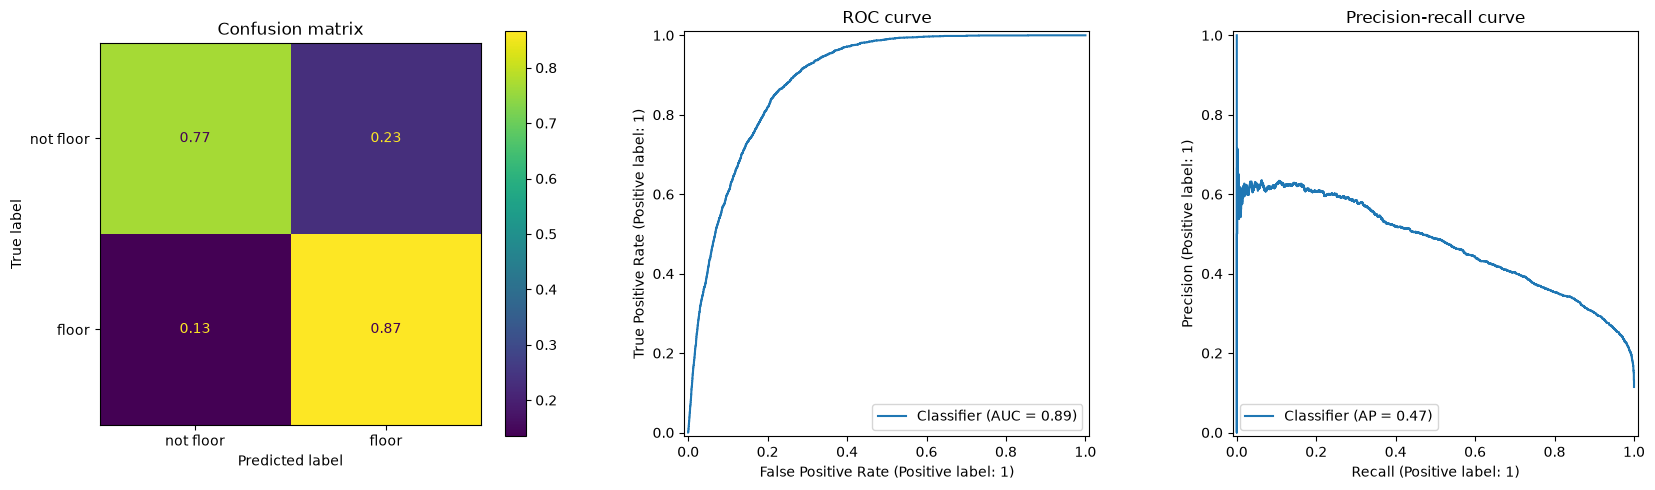

In [5]:
clf_lr = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000))
clf_lr.fit(X_train, y_train)
evaluate(y_test, clf_lr.predict_proba(X_test)[:, 1])

## Random Forest

AUC:      0.910
AP:       0.572
Accuracy: 0.836  (baseline 'always not floor': 0.885)
IoU:      0.361
              precision    recall  f1-score   support

   not floor       0.97      0.84      0.90     19035
       floor       0.39      0.81      0.53      2465

    accuracy                           0.84     21500
   macro avg       0.68      0.82      0.72     21500
weighted avg       0.91      0.84      0.86     21500



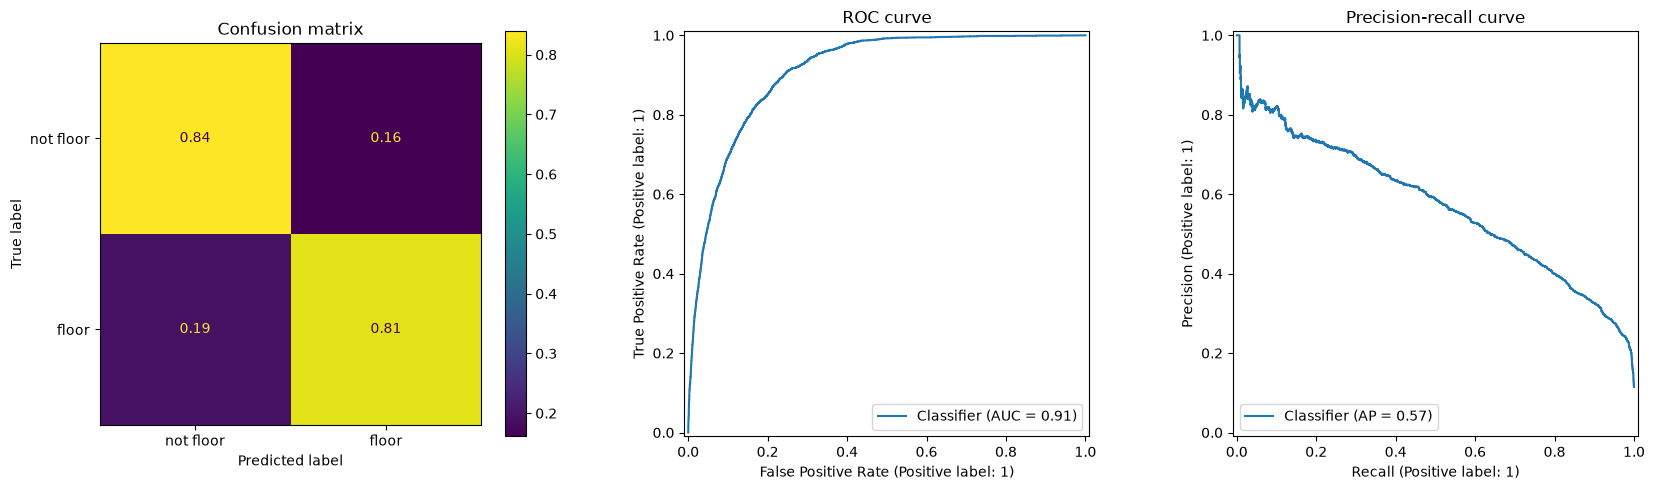

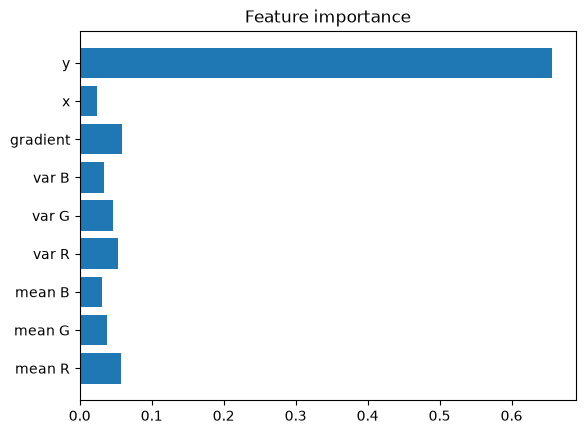

In [6]:
clf_rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=20,
                                class_weight="balanced_subsample",
                                n_jobs=-1, random_state=RANDOM_STATE)
clf_rf.fit(X_train, y_train)
evaluate(y_test, clf_rf.predict_proba(X_test)[:, 1])

plt.barh(FEATURE_NAMES, clf_rf.feature_importances_)
plt.title("Feature importance")
plt.show()

## SVM

AUC:      0.886
AP:       0.426
Accuracy: 0.763  (baseline 'always not floor': 0.885)
IoU:      0.302
              precision    recall  f1-score   support

   not floor       0.98      0.75      0.85     19035
       floor       0.31      0.89      0.46      2465

    accuracy                           0.76     21500
   macro avg       0.65      0.82      0.66     21500
weighted avg       0.91      0.76      0.80     21500



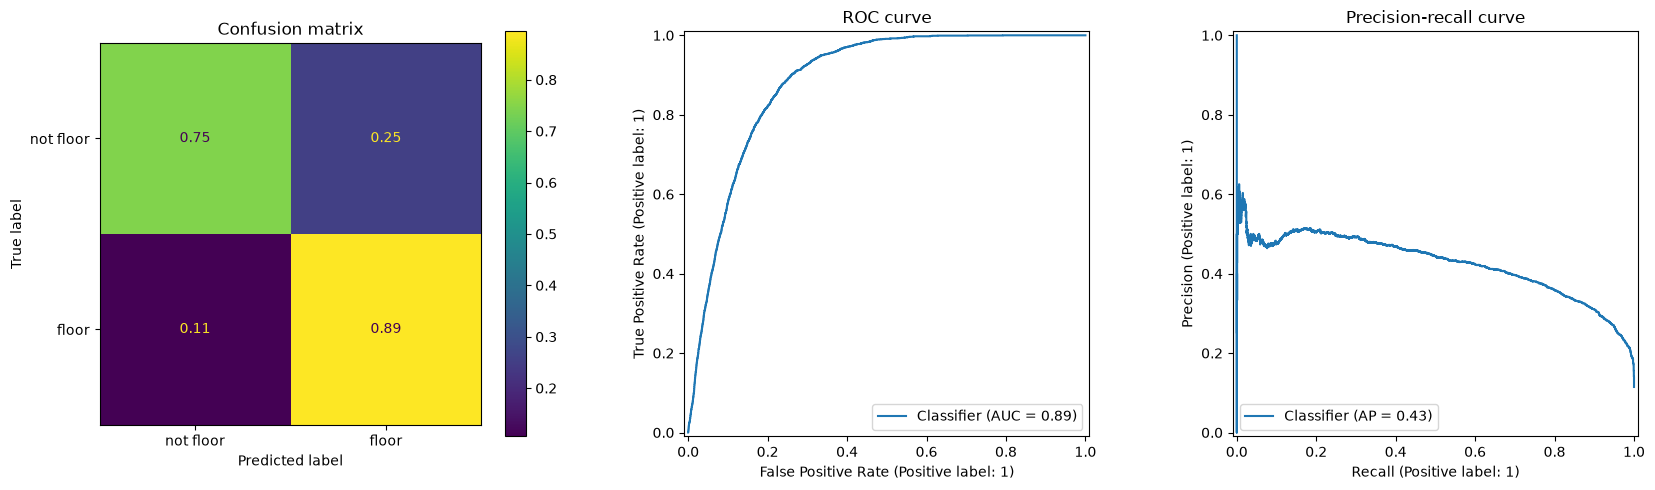

In [7]:
rng = np.random.default_rng(RANDOM_STATE)
subset = rng.choice(len(X_train), size=10000, replace=False)

clf_svm = make_pipeline(StandardScaler(), SVC(class_weight="balanced"))
clf_svm.fit(X_train[subset], y_train[subset])
evaluate(y_test, clf_svm.decision_function(X_test), threshold=0)

MLP

Iteration 1, loss = 0.41765406
Validation score: 0.831646
Iteration 2, loss = 0.37936243
Validation score: 0.834178
Iteration 3, loss = 0.37739179
Validation score: 0.832293
Iteration 4, loss = 0.37425377
Validation score: 0.830789
Iteration 5, loss = 0.37250881
Validation score: 0.836404
Iteration 6, loss = 0.37002967
Validation score: 0.835693
Iteration 7, loss = 0.36808855
Validation score: 0.830503
Iteration 8, loss = 0.36619694
Validation score: 0.835416
Iteration 9, loss = 0.36485938
Validation score: 0.835490
Iteration 10, loss = 0.36274635
Validation score: 0.836959
Iteration 11, loss = 0.36130968
Validation score: 0.836054
Iteration 12, loss = 0.36040824
Validation score: 0.836155
Iteration 13, loss = 0.35900433
Validation score: 0.841514
Iteration 14, loss = 0.35750882
Validation score: 0.836822
Iteration 15, loss = 0.35724530
Validation score: 0.841818
Iteration 16, loss = 0.35637024
Validation score: 0.841632
Iteration 17, loss = 0.35577503
Validation score: 0.841134
Iterat

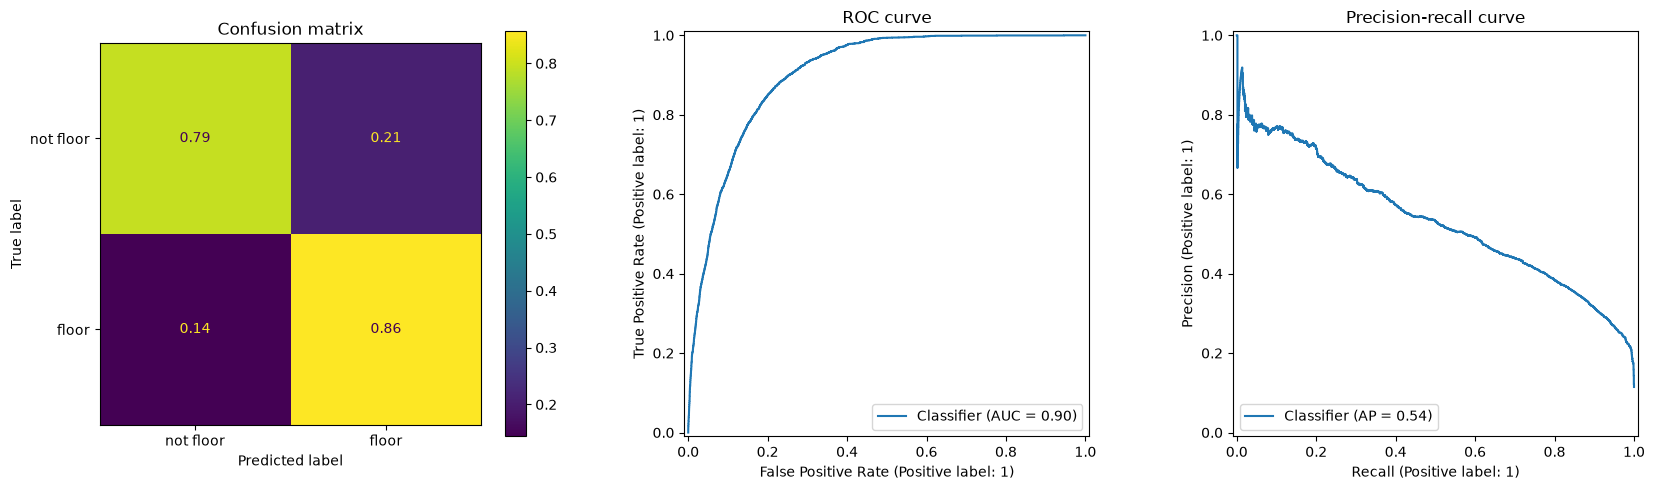

In [8]:
clf_mlp = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(64, 32), batch_size=256,
                        max_iter=30, early_stopping=True, random_state=RANDOM_STATE, verbose=True))
clf_mlp.fit(X_train, y_train,
            mlpclassifier__sample_weight=compute_sample_weight("balanced", y_train))
evaluate(y_test, clf_mlp.predict_proba(X_test)[:, 1])

## Results

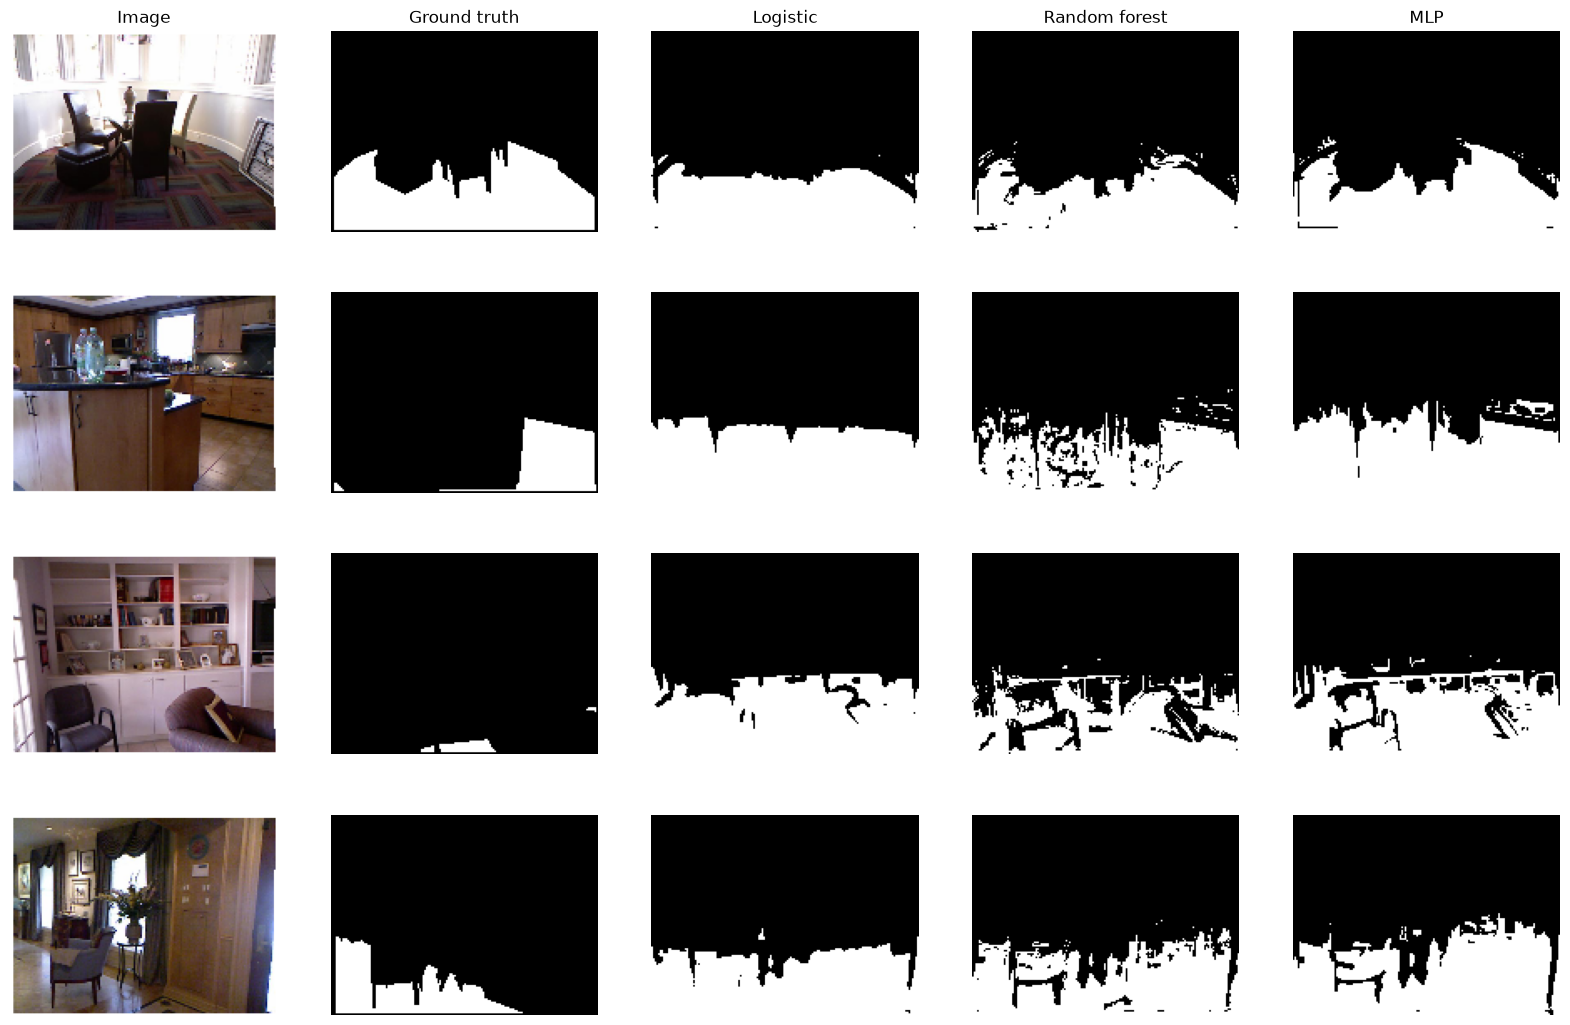

In [9]:
STRIDE = 4   # predict one pixel every 4 (faster)
models = {"Logistic": clf_lr, "Random forest": clf_rf, "MLP": clf_mlp}

fig, axes = plt.subplots(4, 5, figsize=(20, 13))

for row, idx in enumerate(test_indices[:4]):
    image, labels = nyu.get_pair(idx)
    gt = binary_target_mask(labels, target_ids)

    # compute on the full image, then keep one pixel every STRIDE
    maps = patch_feature_maps(image, PATCH_SIZE, WITH_POSITION)[::STRIDE, ::STRIDE]
    X = maps.reshape(-1, maps.shape[2])

    axes[row, 0].imshow(image[::STRIDE, ::STRIDE])
    axes[row, 1].imshow(gt[::STRIDE, ::STRIDE], cmap="gray")
    for k, (name, model) in enumerate(models.items()):
        pred = model.predict_proba(X)[:, 1].reshape(maps.shape[:2]) >= 0.5
        axes[row, 2 + k].imshow(pred, cmap="gray", vmin=0, vmax=1)
        axes[0, 2 + k].set_title(name)

axes[0, 0].set_title("Image")
axes[0, 1].set_title("Ground truth")

for ax in axes.ravel():
    ax.axis("off")

plt.show()